# RuBERT-tiny2: исходный опыт и проверки устойчивости

Исходный seed 42 выполнен на CPU и сохранён. По умолчанию его
обучение пропускается: run_original_baseline=false в конфигурации.
Разделы 11–15 выполняют четыре обучения: seeds 17/123 × две цели.
Вход только operator_log; объединения признаков нет. Разбиение eda_v1
неизменно, test не оценивается. Переформулировки синтетические,
не используются ни для обучения, ни для выбора эпох или порогов.
Повторная настройка по результатам этой проверки не выполняется.


## Окружение и устройство

В следующей ячейке задайте `DEVICE = "cpu"` (локально) или `"cuda"` (NVIDIA). Затем Restart Kernel → Run All. Рабочий каталог — notebooks/experiments; ядро — .venv Python 3.11. CUDA проверяется до загрузки данных; скрытого перехода на CPU нет. Если видны несколько GPU, заранее задайте CUDA_VISIBLE_DEVICES. Оба режима используют один протокол FP32 и два обучения.


In [1]:
import hashlib
import json
import logging
import os
import pickle
import platform
import shutil
import sys
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from itertools import product
from pathlib import Path
from time import perf_counter

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
PROJECT_ROOT = Path("../..").resolve()
if not (PROJECT_ROOT / "configs/04_rubert_tiny2.json").is_file():
    raise RuntimeError("Рабочий каталог должен быть notebooks/experiments.")
if Path(sys.prefix).resolve() != (PROJECT_ROOT / ".venv").resolve():
    raise RuntimeError("Выберите ядро .venv проекта.")
if sys.version_info[:2] != (3, 11):
    raise RuntimeError("Нужен Python 3.11.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.environ.setdefault("HF_HOME", str(PROJECT_ROOT / ".cache/huggingface"))

'C:\\Users\\Mo\\work\\study\\Магистратура\\2к\\1с\\LLMs\\.cache\\huggingface'

In [2]:
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from scipy.special import softmax
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    classification_report,
    confusion_matrix,
)
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

from industrial_maintenance import baseline, data, text_transformer
from industrial_maintenance.comparison import paired_group_bootstrap
from industrial_maintenance.wording_checks import (
    validate_wording_pairs,
    wording_prediction_table,
)

DEVICE = "cpu"  # На сервере замените на "cuda" перед Run All.

CONFIG = json.loads(
    (PROJECT_ROOT / "configs/04_rubert_tiny2.json").read_text(encoding="utf-8")
)
CONFIG["execution"]["device"] = DEVICE
hardware = text_transformer.configure_execution(
    DEVICE, CONFIG["execution"]["cpu_threads"]
)
display(hardware)
assert CONFIG["features"] == ["operator_log"]
assert CONFIG["expected_training_runs"] == len(CONFIG["targets"]) == 2
versions = {
    name: version(name)
    for name in [
        "torch",
        "transformers",
        "accelerate",
        "numpy",
        "pandas",
        "scikit-learn",
        "mlflow",
        "scipy",
    ]
}
display(CONFIG)
display(pd.Series(versions, name="Версия"))

C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/10/18 14:46:11 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


{'device': 'cpu',
 'cpu_threads': 6,
 'logical_cpus': 12,
 'cuda_build': None,
 'gpu': None,
 'gpu_bytes': None}

{'model_id': 'cointegrated/rubert-tiny2',
 'notebook': 'notebooks/experiments/04_rubert_tiny2.ipynb',
 'revision': 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae',
 'features': ['operator_log'],
 'excluded_features': ['required_route',
  'severity',
  'id',
  'failure_within_30d',
  'fault_type'],
 'dataset_config': 'configs/eda_16_10.json',
 'membership_file': 'Data/splits/eda_v1/membership.csv',
 'split_manifest': 'Data/splits/eda_v1/manifest.json',
 'membership_sha256': '7df958804864a5e37776843f66ab7ab358b74a685188df14f60eb83cddea00b1',
 'expected_sizes': {'train': 10655, 'validation': 2193, 'test': 2152},
 'targets': {'failure_within_30d': 'average_precision',
  'fault_type': 'macro_f1'},
 'expected_classes': {'failure_within_30d': [0, 1],
  'fault_type': ['bearing_wear',
   'cavitation',
   'imbalance',
   'normal',
   'overheat',
   'seal_leak']},
 'expected_training_runs': 2,
 'max_length': 128,
 'seed': 42,
 'execution': {'device': 'cpu', 'cpu_threads': 6},
 'training': {'learning_r

torch           2.9.1+cpu
transformers       4.57.6
accelerate         1.12.0
numpy               2.4.6
pandas              3.0.6
scikit-learn        1.9.1
mlflow             3.17.1
scipy              1.17.1
Name: Версия, dtype: str

## 2. Неизменяемые данные и только train/validation

Полный CSV читается для проверки контрольной суммы и разбиения.
После проверки test не передаётся ни в токенизацию, ни в обучение,
ни в оценивание. Исходные журналы не очищаются и не маскируются.

In [3]:
dataset_config = json.loads(
    (PROJECT_ROOT / CONFIG["dataset_config"]).read_text(encoding="utf-8")
)
frame, source_manifest = data.load_dataset(PROJECT_ROOT, dataset_config)
membership_path = PROJECT_ROOT / CONFIG["membership_file"]
assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
split_manifest = json.loads(
    (PROJECT_ROOT / CONFIG["split_manifest"]).read_text(encoding="utf-8")
)
assert split_manifest["protocol"]["sha256"] == source_manifest["sha256"]
assert split_manifest["membership_sha256"] == CONFIG["membership_sha256"]
assert split_manifest["sizes"] == CONFIG["expected_sizes"]
membership = pd.read_csv(membership_path, dtype={"id": "string"})
data.validate_splits(frame, membership)
parts = {}
for split in ["train", "validation"]:
    ids = membership.loc[membership["split"].eq(split), "id"]
    parts[split] = frame.loc[frame["id"].isin(ids)].copy()
    assert len(parts[split]) == CONFIG["expected_sizes"][split]
del frame
train, validation = parts["train"], parts["validation"]
for target, expected_classes in CONFIG["expected_classes"].items():
    assert sorted(train[target].unique().tolist()) == expected_classes
    assert set(validation[target]).issubset(set(expected_classes))
    display(
        pd.DataFrame(
            {
                "train": train[target].value_counts(),
                "validation": validation[target].value_counts(),
            }
        )
    )
display(pd.Series(split_manifest["sizes"], name="Размер выборки"))

,train,validation
failure_within_30d,,
0,8870,1830
1,1785,363


,train,validation
fault_type,,
bearing_wear,1261,255
cavitation,1069,222
imbalance,1147,232
normal,4783,1005
overheat,1215,252
seal_leak,1180,227


train         10655
validation     2193
test           2152
Name: Размер выборки, dtype: int64

## 3. Закреплённые контроли и соответствие id

Читаем TF-IDF, числовой CatBoost и prior из явно указанных запусков.
Модели не переобучаются, их файлы и MLflow не изменяются.
TF-IDF имеет те же входы; CatBoost получает другую информацию.

In [4]:
references = {}
reference_checksums = {}
for reference in CONFIG["references"]:
    batch = PROJECT_ROOT / reference["batch"]
    reference_manifest = json.loads(
        (batch / "manifest.json").read_text(encoding="utf-8")
    )
    assert reference_manifest["status"] == "completed"
    assert not reference_manifest["test_evaluated"]
    assert reference_manifest["source"]["sha256"] == source_manifest["sha256"]
    assert (
        reference_manifest["config"]["membership_sha256"]
        == CONFIG["membership_sha256"]
    )
    assert reference_manifest["split"]["sizes"] == split_manifest["sizes"]
    selected = pd.read_csv(batch / reference["table"])
    selected = selected.loc[selected["variant"].eq(reference["variant"])]
    assert len(selected) == 2
    paths = [batch / "manifest.json", batch / reference["table"]]
    for row in selected.to_dict("records"):
        target = row["target"]
        directory = PROJECT_ROOT / row["run_path"]
        trial = json.loads(
            (directory / "manifest.json").read_text(encoding="utf-8")
        )
        assert sorted(trial["classes"]) == CONFIG["expected_classes"][target]
        assert not set(CONFIG["excluded_features"]).intersection(
            trial["features"]
        )
        predictions = pd.read_csv(
            directory / "validation_predictions.csv",
            dtype={"id": "string"},
            float_precision="round_trip",
        )
        truth = validation.set_index("id")[target]
        assert predictions.id.is_unique
        assert set(predictions.id) == set(truth.index)
        np.testing.assert_array_equal(
            predictions.set_index("id").loc[truth.index, "y_true"], truth
        )
        references[(reference["name"], target)] = {
            "predictions": predictions,
            "directory": directory,
        }
        paths.extend(
            [
                directory / "manifest.json",
                directory / "validation_predictions.csv",
            ]
        )
        if target == "failure_within_30d":
            paths.append(directory / "validation_predictions_f2.csv")
    for path in paths:
        reference_checksums[path.relative_to(PROJECT_ROOT).as_posix()] = (
            data.file_sha256(path)
        )
display(
    pd.DataFrame(
        [
            {
                "control": name,
                "target": target,
                **baseline.classification_metrics(
                    item["predictions"],
                    CONFIG["expected_classes"][target],
                    target,
                ),
            }
            for (name, target), item in references.items()
        ]
    )
)

,control,target,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision
0,tfidf,failure_within_30d,0.832649,0.500820,0.313482,0.452381,0.052342,0.093827,0.063588,0.855282,0.442193
1,tfidf,fault_type,1.000000,1.000000,0.043574,NaN,NaN,NaN,NaN,NaN,NaN
2,catboost_numeric,failure_within_30d,0.892841,0.795255,0.203937,0.702532,0.611570,0.653903,0.627828,0.948259,0.786742
3,catboost_numeric,fault_type,0.807570,0.757161,0.461973,NaN,NaN,NaN,NaN,NaN,NaN
4,prior,failure_within_30d,0.834473,0.454884,0.448736,0.000000,0.000000,0.000000,0.000000,0.500000,0.165527
5,prior,fault_type,0.458276,0.104753,1.561055,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Готовый токенизатор и длина последовательности

Словарь не обучается на наших данных. Ограничение 128 проверяем на train;
если оно обрезает тексты, эксперимент останавливается для явного решения.
Длина validation сохраняется как диагностика без изменения настройки.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(
    CONFIG["model_id"], revision=CONFIG["revision"], trust_remote_code=False
)
length_records = []
for split, part in parts.items():
    texts = text_transformer.text_inputs(part[CONFIG["features"]])
    tokens = tokenizer(texts, truncation=False, padding=False)
    lengths = np.array([len(sequence) for sequence in tokens["input_ids"]])
    length_records.append(
        {
            "split": split,
            "rows": len(lengths),
            "max_tokens": int(lengths.max()),
            "mean_tokens": float(lengths.mean()),
            "truncated_rows": int((lengths > CONFIG["max_length"]).sum()),
        }
    )
    if split == "train" and (lengths > CONFIG["max_length"]).any():
        raise ValueError(
            "max_length обрезает train; сначала уточните настройку."
        )
token_lengths = pd.DataFrame(length_records)
display(token_lengths)

,split,rows,max_tokens,mean_tokens,truncated_rows
0,train,10655,20,18.206851,0
1,validation,2193,20,18.186047,0


## 5. Устройство, новый каталог и исходный код

CPU или CUDA уже проверены в начале тетради. Каждый запуск создаёт
новый каталог и сохраняет все эпохи для восстановления. Режим CPU
использует шесть потоков; CUDA — один видимый NVIDIA GPU.
Автоматических повторов или возобновлений нет. Инструкция переноса:
../../TRANSFORMER_SERVER.md.


In [6]:
if CONFIG["run_original_baseline"]:
    started = datetime.now(timezone.utc)
    batch_id = CONFIG["batch_prefix"] + started.strftime("%Y%m%dT%H%M%S_%fZ")
    batch_directory = PROJECT_ROOT / CONFIG["output_root"] / batch_id
    batch_directory.mkdir(parents=True, exist_ok=False)

    def write_json(path, value):
        """Сохранить JSON в UTF-8 без нечисловых значений NaN."""
        path.write_text(
            json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),
            encoding="utf-8",
        )

    logger = logging.getLogger(CONFIG["experiment_name"])
    for handler in list(logger.handlers):
        handler.close()
        logger.removeHandler(handler)
    logger.setLevel(logging.INFO)
    logger.propagate = False
    for handler in [
        logging.StreamHandler(sys.stdout),
        logging.FileHandler(batch_directory / "run.log", encoding="utf-8"),
    ]:
        handler.setFormatter(logging.Formatter("%(asctime)s %(message)s"))
        logger.addHandler(handler)
    hardware.update({"platform": platform.platform(), "python": sys.version})
    source_directory = batch_directory / "source"
    source_directory.mkdir()
    source_checksums = {}
    for relative in [*CONFIG["source_files"], "pyproject.toml", "uv.lock"]:
        path = PROJECT_ROOT / relative
        destination = source_directory / relative
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, destination)
        source_checksums[relative] = data.file_sha256(path)
    notebook = json.loads(
        (PROJECT_ROOT / CONFIG["notebook"]).read_text(encoding="utf-8")
    )
    notebook_code = "\n\n".join(
        "".join(cell["source"])
        for cell in notebook["cells"]
        if cell["cell_type"] == "code"
    )
    (source_directory / "notebook_code.py").write_text(
        notebook_code, encoding="utf-8"
    )
    manifest = {
        "status": "running",
        "batch_id": batch_id,
        "config": CONFIG,
        "source": source_manifest,
        "split": split_manifest,
        "libraries": versions,
        "hardware": hardware,
        "source_checksums": source_checksums,
        "notebook_code_sha256": hashlib.sha256(
            notebook_code.encode("utf-8")
        ).hexdigest(),
        "reference_checksums": reference_checksums,
        "started_at_utc": started.isoformat(),
        "test_evaluated": False,
        "completed_training_runs": 0,
    }
    write_json(batch_directory / "manifest.json", manifest)
    write_json(batch_directory / "config.json", CONFIG)
    token_lengths.to_csv(batch_directory / "token_lengths.csv", index=False)
    tracking_database = PROJECT_ROOT / CONFIG["tracking_database"]
    tracking_database.parent.mkdir(parents=True, exist_ok=True)
    tracking_artifacts = PROJECT_ROOT / CONFIG["tracking_artifacts"]
    tracking_artifacts.mkdir(parents=True, exist_ok=True)
    mlflow.set_tracking_uri("sqlite:///" + tracking_database.as_posix())
    experiment = mlflow.get_experiment_by_name(CONFIG["experiment_name"])
    experiment_id = (
        experiment.experiment_id
        if experiment
        else mlflow.create_experiment(
            CONFIG["experiment_name"],
            artifact_location=tracking_artifacts.as_uri(),
        )
    )
    logger.info("Начало %s; два обучения; %s", batch_id, hardware["device"])

## 6. Два независимых обучения и выбор эпохи

Каждая модель заново загружает исходные веса. Cross-entropy без весов
классов, AdamW и линейное расписание заданы конфигурацией. Encoder
полностью обучаемый. Validation используется только для оценки эпох.
Сохраняем checkpoints, журнал потерь, предупреждения и выбранную модель.
Один MLflow run на цель; оценивание и порог новых run не создают.

In [7]:
if CONFIG["run_original_baseline"]:
    results = []
    prediction_tables = {}
    reloaded_predictions = {}
    for target, primary_metric in CONFIG["targets"].items():
        classes = CONFIG["expected_classes"][target]
        set_seed(CONFIG["seed"])
        datasets = {
            split: text_transformer.TextDataset(
                part[CONFIG["features"]],
                part[target],
                classes,
                tokenizer,
                CONFIG["max_length"],
            )
            for split, part in parts.items()
        }

        def evaluate_epoch(output):
            """Рассчитать метрики эпохи на неизменной validation."""
            # 1) Сопоставить выходы с метками в порядке validation.
            predictions = text_transformer.predictions_from_logits(
                validation.id,
                validation[target],
                output.predictions,
                classes,
                target,
                CONFIG["binary_threshold"],
            )
            # 2) Использовать прежние определения метрик.
            return baseline.classification_metrics(
                predictions, classes, target
            )

        with mlflow.start_run(
            experiment_id=experiment_id,
            run_name=batch_id + "_" + target,
            tags={"batch_id": batch_id, "target": target, "system": "B"},
        ) as active_run:
            run_id = active_run.info.run_id
            directory = batch_directory / "runs" / run_id
            directory.mkdir(parents=True)
            trial = {
                **manifest,
                "status": "running",
                "target": target,
                "classes": classes,
                "features": CONFIG["features"],
                "run_id": run_id,
            }
            write_json(directory / "manifest.json", trial)
            write_json(directory / "config.json", CONFIG)
            clock = perf_counter()
            try:
                with warnings.catch_warnings(record=True) as recorded_warnings:
                    warnings.simplefilter("always")
                    model = text_transformer.build_text_classifier(
                        CONFIG["model_id"], CONFIG["revision"], classes
                    )
                    assert all(
                        parameter.requires_grad
                        for parameter in model.parameters()
                    )
                    trainable_parameters = sum(
                        parameter.numel() for parameter in model.parameters()
                    )
                    arguments = TrainingArguments(
                        output_dir=str(directory / "checkpoints"),
                        seed=CONFIG["seed"],
                        data_seed=CONFIG["seed"],
                        disable_tqdm=True,
                        use_cpu=(DEVICE == "cpu"),
                        **CONFIG["training"],
                    )
                    trainer = Trainer(
                        model=model,
                        args=arguments,
                        train_dataset=datasets["train"],
                        eval_dataset=datasets["validation"],
                        processing_class=tokenizer,
                        data_collator=DataCollatorWithPadding(tokenizer),
                        compute_metrics=evaluate_epoch,
                    )
                    logger.info("Обучение %s, MLflow %s", target, run_id)
                    clock = perf_counter()
                    trainer.train()
                    fit_seconds = perf_counter() - clock
                    history = trainer.state.log_history
                    write_json(
                        directory / "training_summary.json",
                        {
                            "fit_seconds": fit_seconds,
                            "history": history,
                        },
                    )
                    best = text_transformer.select_epoch(
                        history, primary_metric, CONFIG["selection_decimals"]
                    )
                    best_checkpoint = (
                        directory
                        / "checkpoints"
                        / ("checkpoint-" + str(best["step"]))
                    )
                    del trainer, model
                    if DEVICE == "cuda":
                        torch.cuda.empty_cache()
                    model = AutoModelForSequenceClassification.from_pretrained(
                        best_checkpoint,
                        use_safetensors=True,
                        attn_implementation="eager",
                    )
                    model.save_pretrained(directory / "model")
                    tokenizer.save_pretrained(directory / "model")
                    trainer = text_transformer.build_prediction_trainer(
                        model, arguments, tokenizer
                    )
                    metrics = {}
                    for split, part in parts.items():
                        inference_clock = perf_counter()
                        logits = trainer.predict(datasets[split]).predictions
                        predictions = text_transformer.predictions_from_logits(
                            part.id,
                            part[target],
                            logits,
                            classes,
                            target,
                            CONFIG["binary_threshold"],
                        )
                        assert predictions.id.tolist() == part.id.tolist()
                        prediction_tables[(target, split)] = predictions
                        predictions.to_csv(
                            directory / f"{split}_predictions.csv", index=False
                        )
                        metrics[split] = baseline.classification_metrics(
                            predictions, classes, target
                        )
                        metrics[split]["prediction_seconds"] = (
                            perf_counter() - inference_clock
                        )
                    restored = (
                        AutoModelForSequenceClassification.from_pretrained(
                            directory / "model", attn_implementation="eager"
                        )
                    )
                    del trainer, model
                    if DEVICE == "cuda":
                        torch.cuda.empty_cache()
                    restored_trainer = (
                        text_transformer.build_prediction_trainer(
                            restored, arguments, tokenizer
                        )
                    )
                    reloaded = text_transformer.predictions_from_logits(
                        validation.id,
                        validation[target],
                        restored_trainer.predict(
                            datasets["validation"]
                        ).predictions,
                        classes,
                        target,
                        CONFIG["binary_threshold"],
                    )
                    columns = [f"probability_{label}" for label in classes]
                    np.testing.assert_allclose(
                        reloaded[columns],
                        prediction_tables[(target, "validation")][columns],
                        rtol=1e-6,
                        atol=1e-7,
                    )
                    np.testing.assert_array_equal(
                        reloaded.y_pred,
                        prediction_tables[(target, "validation")].y_pred,
                    )
                    reloaded_predictions[target] = reloaded
                    del restored_trainer, restored
                    if DEVICE == "cuda":
                        torch.cuda.empty_cache()
                warning_text = "\n".join(
                    str(item.message) for item in recorded_warnings
                )
                (directory / "warnings.log").write_text(
                    warning_text, encoding="utf-8"
                )
                write_json(directory / "history.json", history)
                write_json(directory / "metrics.json", metrics)
                trial.update(
                    {
                        "status": "completed",
                        "best_epoch": best,
                        "fit_seconds": fit_seconds,
                        "reload_verified": True,
                        "trainable_parameters": trainable_parameters,
                    }
                )
                write_json(directory / "manifest.json", trial)
                mlflow.log_params(
                    {
                        "model_id": CONFIG["model_id"],
                        "revision": CONFIG["revision"],
                        "target": target,
                        "features": "operator_log",
                        "seed": CONFIG["seed"],
                        **CONFIG["execution"],
                        **CONFIG["training"],
                    }
                )
                mlflow.log_metrics(
                    {
                        f"{split}_{name}": value
                        for split, values in metrics.items()
                        for name, value in values.items()
                        if value is not None
                    }
                )
                mlflow.log_metric("fit_seconds", fit_seconds)
                for row in history:
                    mlflow.log_metrics(
                        {
                            key: float(value)
                            for key, value in row.items()
                            if isinstance(value, (int, float))
                            and key != "step"
                        },
                        step=int(row["step"]),
                    )
                for path in directory.glob("*.*"):
                    mlflow.log_artifact(str(path))
                mlflow.log_artifacts(str(directory / "model"), "model")
                results.append(
                    {
                        "target": target,
                        "run_id": run_id,
                        "run_path": directory.relative_to(
                            PROJECT_ROOT
                        ).as_posix(),
                        "best_epoch": best["epoch"],
                        "fit_seconds": fit_seconds,
                        **metrics["validation"],
                    }
                )
                manifest["completed_training_runs"] = len(results)
                write_json(batch_directory / "manifest.json", manifest)
                logger.info("Завершено %s: эпоха %s", target, best["epoch"])
            except Exception as error:
                trial.update({"status": "failed", "error": repr(error)})
                manifest.update({"status": "failed", "error": repr(error)})
                write_json(directory / "manifest.json", trial)
                write_json(batch_directory / "manifest.json", manifest)
                logger.exception("Опыт остановлен без повторного обучения")
                raise
    selected_models = pd.DataFrame(results)
    selected_models.to_csv(
        batch_directory / "selected_models.csv", index=False
    )
    display(selected_models)

## 7. Кривые обучения, классы и ошибки

Показываем метрики выбранных эпох, отчёты по классам, матрицы ошибок,
PR/ROC отказа и подгруппы equipment/severity. Последние не являются
входами модели. Сохраняем до 20 ошибок на цель, если ошибки существуют.

In [8]:
if CONFIG["run_original_baseline"]:
    for row in results:
        target = row["target"]
        classes = CONFIG["expected_classes"][target]
        directory = PROJECT_ROOT / row["run_path"]
        predictions = prediction_tables[(target, "validation")]
        history = json.loads((directory / "history.json").read_text())
        history_frame = pd.DataFrame(history)
        metric = "eval_" + CONFIG["targets"][target]
        figure, axes = plt.subplots(1, 2, figsize=(11, 4))
        history_frame.dropna(subset=["loss"]).plot(
            x="epoch", y="loss", ax=axes[0], label="Train loss"
        )
        history_frame.dropna(subset=["eval_loss"]).plot(
            x="epoch", y="eval_loss", ax=axes[0], label="Validation loss"
        )
        history_frame.dropna(subset=[metric]).plot(
            x="epoch", y=metric, ax=axes[1], label=metric
        )
        figure.tight_layout()
        figure.savefig(directory / "learning_curves.png")
        plt.show()
        plt.close(figure)
        report = pd.DataFrame(
            classification_report(
                predictions.y_true,
                predictions.y_pred,
                labels=classes,
                output_dict=True,
                zero_division=0,
            )
        ).T
        report.to_csv(directory / "classification_report.csv")
        display(Markdown(f"### {target}"))
        display(report)
        matrix = confusion_matrix(
            predictions.y_true, predictions.y_pred, labels=classes
        )
        pd.DataFrame(matrix, index=classes, columns=classes).to_csv(
            directory / "confusion_matrix.csv"
        )
        figure, axis = plt.subplots(figsize=(8, 6))
        ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
            ax=axis, colorbar=False, xticks_rotation=35
        )
        figure.tight_layout()
        figure.savefig(directory / "confusion_matrix.png")
        plt.show()
        plt.close(figure)
        diagnosis = predictions.merge(
            validation[["id", "operator_log", "equipment", "severity"]],
            on="id",
            validate="one_to_one",
        )
        errors = diagnosis.loc[diagnosis.y_true.ne(diagnosis.y_pred)]
        errors.head(CONFIG["error_examples"]).to_csv(
            directory / "error_examples.csv", index=False
        )
        display(Markdown(f"Ошибок validation: **{len(errors)}**."))
        display(errors.head(CONFIG["error_examples"]))
        subgroups = []
        for grouping in ["equipment", "severity"]:
            for value, group in diagnosis.groupby(grouping):
                subgroups.append(
                    {
                        "grouping": grouping,
                        "value": value,
                        "rows": len(group),
                        **baseline.classification_metrics(
                            group, classes, target
                        ),
                    }
                )
        pd.DataFrame(subgroups).to_csv(
            directory / "subgroups.csv", index=False
        )
        if target == "failure_within_30d":
            figure, axes = plt.subplots(1, 2, figsize=(11, 4))
            PrecisionRecallDisplay.from_predictions(
                predictions.y_true, predictions.probability_1, ax=axes[0]
            )
            RocCurveDisplay.from_predictions(
                predictions.y_true, predictions.probability_1, ax=axes[1]
            )
            figure.tight_layout()
            figure.savefig(directory / "pr_roc.png")
            plt.show()
            plt.close(figure)

## 8. F2-порог после выбора эпохи

Сохраняем исходные прогнозы при 0,5. Порог не меняет вероятности,
AP или ROC-AUC. Решение положительно при probability_1 >= threshold.
Файл decision_rule.json хранится рядом с моделью; from_pretrained сам
по себе этот порог не применяет. Для применения нужна та же явная проверка.
Дополнительные точки precision ≥ 70%/80% — только диагностика.

In [9]:
if CONFIG["run_original_baseline"]:
    binary_target = "failure_within_30d"
    binary_row = next(row for row in results if row["target"] == binary_target)
    binary_directory = PROJECT_ROOT / binary_row["run_path"]
    original = prediction_tables[(binary_target, "validation")]
    best_threshold, curve = baseline.select_failure_threshold(
        original.y_true, original.probability_1, CONFIG["selection_decimals"]
    )
    np.testing.assert_array_equal(
        original.probability_1.ge(best_threshold["threshold"]),
        reloaded_predictions[binary_target].probability_1.ge(
            best_threshold["threshold"]
        ),
    )
    curve.to_csv(binary_directory / "threshold_curve.csv", index=False)
    write_json(
        binary_directory / "model/decision_rule.json",
        {
            "positive_class": 1,
            "threshold": best_threshold["threshold"],
            "rule": "probability_1 >= threshold",
            "selection_split": "validation",
            "selection_metric": "f2",
            "refit": False,
        },
    )
    threshold_metrics = []
    for split in ["train", "validation"]:
        predictions = prediction_tables[(binary_target, split)].copy()
        predictions["y_pred"] = predictions.probability_1.ge(
            best_threshold["threshold"]
        ).astype(int)
        predictions.to_csv(
            binary_directory / f"{split}_predictions_f2.csv", index=False
        )
        before = baseline.classification_metrics(
            prediction_tables[(binary_target, split)], [0, 1], binary_target
        )
        after = baseline.classification_metrics(
            predictions, [0, 1], binary_target
        )
        assert before["average_precision"] == after["average_precision"]
        assert before["roc_auc"] == after["roc_auc"]
        for name, values in [("default_0.5", before), ("selected_f2", after)]:
            threshold_metrics.append({"split": split, "rule": name, **values})
        prediction_tables[(binary_target, split + "_f2")] = predictions
        if split == "validation":
            pd.DataFrame(
                confusion_matrix(
                    predictions.y_true, predictions.y_pred, labels=[0, 1]
                ),
                index=[0, 1],
                columns=[0, 1],
            ).to_csv(binary_directory / "confusion_matrix_f2.csv")
    pd.DataFrame(threshold_metrics).to_csv(
        binary_directory / "threshold_metrics.csv", index=False
    )
    operating_points = [
        baseline.precision_recall_operating_point(
            curve, floor, CONFIG["selection_decimals"]
        )
        for floor in CONFIG["precision_floors"]
    ]
    pd.DataFrame(operating_points).to_csv(
        binary_directory / "precision_operating_points.csv", index=False
    )
    display(pd.DataFrame(threshold_metrics))
    display(pd.DataFrame(operating_points))
    with mlflow.start_run(run_id=binary_row["run_id"]):
        mlflow.log_param("f2_threshold", best_threshold["threshold"])
        mlflow.log_metrics(
            {
                "validation_f2_threshold_" + key: value
                for key, value in baseline.classification_metrics(
                    prediction_tables[(binary_target, "validation_f2")],
                    [0, 1],
                    binary_target,
                ).items()
                if value is not None
            }
        )

## 9. Парные групповые сравнения

Шесть сравнений AP/macro-F1: каждая цель против TF-IDF, числового CatBoost
и prior. Ещё три F2: выбранный порог против 0,5 и против сохранённых
F2-решений TF-IDF/CatBoost. В каждом — 2 000 повторов, группы eda_v1
переносятся целиком. Пороги фиксированы, повторного обучения нет.
Интервалы условны относительно выбора эпохи и порога на той же validation;
они могут быть оптимистичными и не заменяют итоговый test.

In [10]:
if CONFIG["run_original_baseline"]:
    validation_groups = membership.loc[
        membership["split"].eq("validation"), ["id", "group_id"]
    ]
    comparisons = []
    for (name, target), reference in references.items():
        comparisons.append(
            {
                "target": target,
                "reference": name,
                **paired_group_bootstrap(
                    reference["predictions"],
                    prediction_tables[(target, "validation")],
                    validation_groups,
                    CONFIG["expected_classes"][target],
                    target,
                    **CONFIG["bootstrap"],
                ),
            }
        )
    f2_references = {"default_0.5": original}
    for name in ["tfidf", "catboost_numeric"]:
        f2_references[name] = pd.read_csv(
            references[(name, binary_target)]["directory"]
            / "validation_predictions_f2.csv",
            dtype={"id": "string"},
            float_precision="round_trip",
        )
    for name, predictions in f2_references.items():
        comparisons.append(
            {
                "target": binary_target,
                "reference": name,
                **paired_group_bootstrap(
                    predictions,
                    prediction_tables[(binary_target, "validation_f2")],
                    validation_groups,
                    [0, 1],
                    binary_target,
                    metric="f2",
                    **CONFIG["bootstrap"],
                ),
            }
        )
    assert len(comparisons) == 9
    comparison_results = pd.DataFrame(comparisons)
    comparison_results.to_csv(
        batch_directory / "paired_bootstrap.csv", index=False
    )
    display(comparison_results)

## 10. Завершение и проверяемая сводка

Успешный опыт — два обучения и две завершённые записи MLflow, сохранённые
модели/токенизатор, исходные прогнозы, порог, кривые и девять сравнений.
Результат сохраняется независимо от направления разности с контролями.
Здесь нет объединения признаков, поиска настроек или оценки test.

In [11]:
if CONFIG["run_original_baseline"]:
    assert len(results) == CONFIG["expected_training_runs"]
    assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
    assert (
        data.file_sha256(PROJECT_ROOT / dataset_config["dataset"])
        == dataset_config["sha256"]
    )
    for relative, checksum in reference_checksums.items():
        assert data.file_sha256(PROJECT_ROOT / relative) == checksum
    for row in results:
        with mlflow.start_run(run_id=row["run_id"]):
            directory = PROJECT_ROOT / row["run_path"]
            for path in directory.iterdir():
                if path.is_file():
                    mlflow.log_artifact(str(path))
            if row["target"] == binary_target:
                mlflow.log_artifact(
                    str(directory / "model/decision_rule.json")
                )
        assert mlflow.get_run(row["run_id"]).info.status == "FINISHED"
    manifest.update(
        {
            "status": "completed",
            "finished_at_utc": datetime.now(timezone.utc).isoformat(),
            "selected_models": results,
            "bootstrap_comparisons": len(comparisons),
            "threshold": best_threshold,
            "test_evaluated": False,
        }
    )
    write_json(batch_directory / "manifest.json", manifest)
    summary = [
        "# RuBERT-tiny2: выполненный опыт B",
        "",
        "Два независимых обучения, один seed, пять эпох; вход operator_log.",
        "Test не оценивался. Число сравнений: 9.",
        "",
    ]
    for row in results:
        metric = CONFIG["targets"][row["target"]]
        summary.append(
            f"- {row['target']}: {metric}={row[metric]:.6f}; "
            f"эпоха={row['best_epoch']}; fit={row['fit_seconds']:.2f} с."
        )
    summary.extend(
        [
            "",
            f"F2-порог: {best_threshold['threshold']!r}.",
            "",
            "Выбор эпохи и порога на одной validation; оценки условны.",
            "Шесть шаблонов ограничивают перенос на неизвестные формулировки.",
            "Бутстрэп не оценивает вариативность повторного обучения.",
        ]
    )
    (batch_directory / "summary.md").write_text(
        "\n".join(summary), encoding="utf-8"
    )
    logger.info("Завершено: %s", batch_directory)
    display(Markdown("\n".join(summary)))

## 11. Два дополнительных seed: неизменный протокол

Четыре новых обучения, без поиска и без выбора лучшего seed.
CPU, шесть потоков, пять эпох; прежние входы, optimizer, FP32,
критерии выбора эпох и F2-порогов. Seed 42 читается по точному пути.
При reuse_fitted_batch тетрадь только читает сохранённые результаты
этой проверки; для нового обучения значение должно быть null.


In [12]:
CHECKS = CONFIG["stability_checks"]
assert CHECKS["seeds"] == [17, 123]
assert CHECKS["expected_training_runs"] == 4
assert not CONFIG["run_original_baseline"]
STAGE_CONFIG = {
    **CONFIG,
    "expected_training_runs": CHECKS["expected_training_runs"],
    "seeds": CHECKS["seeds"],
    "stage": "seed_stability",
    "batch_prefix": CHECKS["batch_prefix"],
    "experiment_name": CHECKS["experiment_name"],
}
reference_batch = PROJECT_ROOT / CHECKS["reference_batch"]
seed42_manifest = json.loads(
    (reference_batch / "manifest.json").read_text(encoding="utf-8")
)
assert seed42_manifest["status"] == "completed"
assert seed42_manifest["config"]["seed"] == CHECKS["reference_seed"]
assert seed42_manifest["source"]["sha256"] == source_manifest["sha256"]
assert (
    seed42_manifest["config"]["membership_sha256"]
    == (CONFIG["membership_sha256"])
)
for name in ["model_id", "revision", "features", "training"]:
    assert seed42_manifest["config"][name] == CONFIG[name]
for source in reference_batch.rglob("*"):
    if source.is_file():
        reference_checksums[source.relative_to(PROJECT_ROOT).as_posix()] = (
            data.file_sha256(source)
        )


def write_json(path, value):
    """Сохранить JSON в UTF-8 без нечисловых значений NaN."""
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )


if CHECKS["reuse_fitted_batch"] is None:
    started = datetime.now(timezone.utc)
    batch_id = STAGE_CONFIG["batch_prefix"] + started.strftime(
        "%Y%m%dT%H%M%S_%fZ"
    )
    batch_directory = PROJECT_ROOT / STAGE_CONFIG["output_root"] / batch_id
    batch_directory.mkdir(parents=True, exist_ok=False)

    logger = logging.getLogger(STAGE_CONFIG["experiment_name"])
    for handler in list(logger.handlers):
        handler.close()
        logger.removeHandler(handler)
    logger.setLevel(logging.INFO)
    logger.propagate = False
    for handler in [
        logging.StreamHandler(sys.stdout),
        logging.FileHandler(batch_directory / "run.log", encoding="utf-8"),
    ]:
        handler.setFormatter(logging.Formatter("%(asctime)s %(message)s"))
        logger.addHandler(handler)
    hardware.update({"platform": platform.platform(), "python": sys.version})
    source_directory = batch_directory / "source"
    source_directory.mkdir()
    source_checksums = {}
    for relative in [
        *STAGE_CONFIG["source_files"],
        "pyproject.toml",
        "uv.lock",
    ]:
        path = PROJECT_ROOT / relative
        destination = source_directory / relative
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(path, destination)
        source_checksums[relative] = data.file_sha256(path)
    notebook = json.loads(
        (PROJECT_ROOT / STAGE_CONFIG["notebook"]).read_text(encoding="utf-8")
    )
    notebook_code = "\n\n".join(
        "".join(cell["source"])
        for cell in notebook["cells"]
        if cell["cell_type"] == "code"
    )
    (source_directory / "notebook_code.py").write_text(
        notebook_code, encoding="utf-8"
    )
    manifest = {
        "status": "running",
        "batch_id": batch_id,
        "config": STAGE_CONFIG,
        "source": source_manifest,
        "split": split_manifest,
        "libraries": versions,
        "hardware": hardware,
        "source_checksums": source_checksums,
        "notebook_code_sha256": hashlib.sha256(
            notebook_code.encode("utf-8")
        ).hexdigest(),
        "reference_checksums": reference_checksums,
        "started_at_utc": started.isoformat(),
        "test_evaluated": False,
        "completed_training_runs": 0,
    }
    write_json(batch_directory / "manifest.json", manifest)
    write_json(batch_directory / "config.json", STAGE_CONFIG)
    token_lengths.to_csv(batch_directory / "token_lengths.csv", index=False)
    tracking_database = PROJECT_ROOT / STAGE_CONFIG["tracking_database"]
    tracking_database.parent.mkdir(parents=True, exist_ok=True)
    tracking_artifacts = PROJECT_ROOT / STAGE_CONFIG["tracking_artifacts"]
    tracking_artifacts.mkdir(parents=True, exist_ok=True)
    mlflow.set_tracking_uri("sqlite:///" + tracking_database.as_posix())
    experiment = mlflow.get_experiment_by_name(STAGE_CONFIG["experiment_name"])
    experiment_id = (
        experiment.experiment_id
        if experiment
        else mlflow.create_experiment(
            STAGE_CONFIG["experiment_name"],
            artifact_location=tracking_artifacts.as_uri(),
        )
    )
    logger.info("Начало %s; четыре обучения; %s", batch_id, hardware["device"])
else:
    batch_directory = PROJECT_ROOT / CHECKS["reuse_fitted_batch"]
    manifest = json.loads(
        (batch_directory / "manifest.json").read_text(encoding="utf-8")
    )
    assert manifest["status"] == "completed"
    assert manifest["completed_training_runs"] == 4
    assert manifest["config"]["seeds"] == CHECKS["seeds"]
    assert manifest["source"]["sha256"] == source_manifest["sha256"]
    results = pd.read_csv(batch_directory / "selected_models.csv").to_dict(
        "records"
    )
    display(Markdown("Сохранённые четыре обучения читаются без нового fit."))

2026-10-18 14:46:21,976 Начало rubert_tiny2_seed_checks_20261018T114619_318668Z; четыре обучения; cpu


## 12. Четыре обучения и сохранение всех эпох

Каждая пара seed/цель заново загружает исходный checkpoint.
Один MLflow run на обучение. Данные и правила выбора одинаковы;
seed не является дополнительным гиперпараметром для отбора.


In [13]:
if CHECKS["reuse_fitted_batch"] is None:
    results = []
    prediction_tables = {}
    reloaded_predictions = {}
    for experiment_seed, target in product(CHECKS["seeds"], CONFIG["targets"]):
        primary_metric = CONFIG["targets"][target]
        classes = CONFIG["expected_classes"][target]
        set_seed(experiment_seed)
        datasets = {
            split: text_transformer.TextDataset(
                part[CONFIG["features"]],
                part[target],
                classes,
                tokenizer,
                CONFIG["max_length"],
            )
            for split, part in parts.items()
        }

        def evaluate_epoch(output):
            """Рассчитать метрики эпохи на неизменной validation."""
            # 1) Сопоставить выходы с метками в порядке validation.
            predictions = text_transformer.predictions_from_logits(
                validation.id,
                validation[target],
                output.predictions,
                classes,
                target,
                CONFIG["binary_threshold"],
            )
            # 2) Использовать прежние определения метрик.
            return baseline.classification_metrics(
                predictions, classes, target
            )

        with mlflow.start_run(
            experiment_id=experiment_id,
            run_name=batch_id + "_" + str(experiment_seed) + "_" + target,
            tags={
                "batch_id": batch_id,
                "target": target,
                "seed": str(experiment_seed),
                "system": "B",
            },
        ) as active_run:
            run_id = active_run.info.run_id
            directory = batch_directory / "runs" / run_id
            directory.mkdir(parents=True)
            trial = {
                **manifest,
                "status": "running",
                "target": target,
                "classes": classes,
                "features": CONFIG["features"],
                "run_id": run_id,
                "seed": experiment_seed,
                "config": {**STAGE_CONFIG, "seed": experiment_seed},
            }
            write_json(directory / "manifest.json", trial)
            write_json(
                directory / "config.json",
                {
                    **STAGE_CONFIG,
                    "seed": experiment_seed,
                },
            )
            clock = perf_counter()
            try:
                with warnings.catch_warnings(record=True) as recorded_warnings:
                    warnings.simplefilter("always")
                    model = text_transformer.build_text_classifier(
                        CONFIG["model_id"], CONFIG["revision"], classes
                    )
                    assert all(
                        parameter.requires_grad
                        for parameter in model.parameters()
                    )
                    trainable_parameters = sum(
                        parameter.numel() for parameter in model.parameters()
                    )
                    arguments = TrainingArguments(
                        output_dir=str(directory / "checkpoints"),
                        seed=experiment_seed,
                        data_seed=experiment_seed,
                        disable_tqdm=True,
                        use_cpu=(DEVICE == "cpu"),
                        **CONFIG["training"],
                    )
                    trainer = Trainer(
                        model=model,
                        args=arguments,
                        train_dataset=datasets["train"],
                        eval_dataset=datasets["validation"],
                        processing_class=tokenizer,
                        data_collator=DataCollatorWithPadding(tokenizer),
                        compute_metrics=evaluate_epoch,
                    )
                    logger.info("Обучение %s, MLflow %s", target, run_id)
                    clock = perf_counter()
                    trainer.train()
                    fit_seconds = perf_counter() - clock
                    history = trainer.state.log_history
                    write_json(
                        directory / "training_summary.json",
                        {
                            "fit_seconds": fit_seconds,
                            "history": history,
                        },
                    )
                    best = text_transformer.select_epoch(
                        history, primary_metric, CONFIG["selection_decimals"]
                    )
                    best_checkpoint = (
                        directory
                        / "checkpoints"
                        / ("checkpoint-" + str(best["step"]))
                    )
                    del trainer, model
                    if DEVICE == "cuda":
                        torch.cuda.empty_cache()
                    model = AutoModelForSequenceClassification.from_pretrained(
                        best_checkpoint,
                        use_safetensors=True,
                        attn_implementation="eager",
                    )
                    model.save_pretrained(directory / "model")
                    tokenizer.save_pretrained(directory / "model")
                    trainer = text_transformer.build_prediction_trainer(
                        model, arguments, tokenizer
                    )
                    metrics = {}
                    for split, part in parts.items():
                        inference_clock = perf_counter()
                        logits = trainer.predict(datasets[split]).predictions
                        predictions = text_transformer.predictions_from_logits(
                            part.id,
                            part[target],
                            logits,
                            classes,
                            target,
                            CONFIG["binary_threshold"],
                        )
                        assert predictions.id.tolist() == part.id.tolist()
                        prediction_tables[(experiment_seed, target, split)] = (
                            predictions
                        )
                        predictions.to_csv(
                            directory / f"{split}_predictions.csv", index=False
                        )
                        metrics[split] = baseline.classification_metrics(
                            predictions, classes, target
                        )
                        metrics[split]["prediction_seconds"] = (
                            perf_counter() - inference_clock
                        )
                    restored = (
                        AutoModelForSequenceClassification.from_pretrained(
                            directory / "model", attn_implementation="eager"
                        )
                    )
                    del trainer, model
                    if DEVICE == "cuda":
                        torch.cuda.empty_cache()
                    restored_trainer = (
                        text_transformer.build_prediction_trainer(
                            restored, arguments, tokenizer
                        )
                    )
                    reloaded = text_transformer.predictions_from_logits(
                        validation.id,
                        validation[target],
                        restored_trainer.predict(
                            datasets["validation"]
                        ).predictions,
                        classes,
                        target,
                        CONFIG["binary_threshold"],
                    )
                    columns = [f"probability_{label}" for label in classes]
                    np.testing.assert_allclose(
                        reloaded[columns],
                        prediction_tables[
                            (experiment_seed, target, "validation")
                        ][columns],
                        rtol=1e-6,
                        atol=1e-7,
                    )
                    np.testing.assert_array_equal(
                        reloaded.y_pred,
                        prediction_tables[
                            (experiment_seed, target, "validation")
                        ].y_pred,
                    )
                    reloaded_predictions[(experiment_seed, target)] = reloaded
                    del restored_trainer, restored
                    if DEVICE == "cuda":
                        torch.cuda.empty_cache()
                warning_text = "\n".join(
                    str(item.message) for item in recorded_warnings
                )
                (directory / "warnings.log").write_text(
                    warning_text, encoding="utf-8"
                )
                write_json(directory / "history.json", history)
                write_json(directory / "metrics.json", metrics)
                trial.update(
                    {
                        "status": "completed",
                        "best_epoch": best,
                        "fit_seconds": fit_seconds,
                        "reload_verified": True,
                        "trainable_parameters": trainable_parameters,
                    }
                )
                write_json(directory / "manifest.json", trial)
                mlflow.log_params(
                    {
                        "model_id": CONFIG["model_id"],
                        "revision": CONFIG["revision"],
                        "target": target,
                        "features": "operator_log",
                        "seed": experiment_seed,
                        **CONFIG["execution"],
                        **CONFIG["training"],
                    }
                )
                mlflow.log_metrics(
                    {
                        f"{split}_{name}": value
                        for split, values in metrics.items()
                        for name, value in values.items()
                        if value is not None
                    }
                )
                mlflow.log_metric("fit_seconds", fit_seconds)
                for row in history:
                    mlflow.log_metrics(
                        {
                            key: float(value)
                            for key, value in row.items()
                            if isinstance(value, (int, float))
                            and key != "step"
                        },
                        step=int(row["step"]),
                    )
                for path in directory.glob("*.*"):
                    mlflow.log_artifact(str(path))
                mlflow.log_artifacts(str(directory / "model"), "model")
                results.append(
                    {
                        "target": target,
                        "run_id": run_id,
                        "seed": experiment_seed,
                        "run_path": directory.relative_to(
                            PROJECT_ROOT
                        ).as_posix(),
                        "best_epoch": best["epoch"],
                        "fit_seconds": fit_seconds,
                        **metrics["validation"],
                    }
                )
                manifest["completed_training_runs"] = len(results)
                write_json(batch_directory / "manifest.json", manifest)
                logger.info("Завершено %s: эпоха %s", target, best["epoch"])
            except Exception as error:
                trial.update({"status": "failed", "error": repr(error)})
                manifest.update({"status": "failed", "error": repr(error)})
                write_json(directory / "manifest.json", trial)
                write_json(batch_directory / "manifest.json", manifest)
                logger.exception("Опыт остановлен без повторного обучения")
                raise
    selected_models = pd.DataFrame(results)
    selected_models.to_csv(
        batch_directory / "selected_models.csv", index=False
    )
    display(selected_models)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at cointegrated/rubert-tiny2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


2026-10-18 14:46:23,297 Обучение failure_within_30d, MLflow ce4523392fbc435fbd57746337ace52a


{'loss': 0.3837, 'grad_norm': 1.0846481323242188, 'learning_rate': 4.449265687583445e-05, 'epoch': 1.0}


{'eval_loss': 0.3163836598396301, 'eval_accuracy': 0.8344733242134063, 'eval_macro_f1': 0.45488441461595824, 'eval_log_loss': 0.3163836248644799, 'eval_precision': 0.0, 'eval_recall': 0.0, 'eval_f1': 0.0, 'eval_f2': 0.0, 'eval_roc_auc': 0.8571858676180585, 'eval_average_precision': 0.4446885947245931, 'eval_runtime': 0.7693, 'eval_samples_per_second': 2850.596, 'eval_steps_per_second': 45.495, 'epoch': 1.0}


{'loss': 0.3162, 'grad_norm': 1.60237717628479, 'learning_rate': 3.3377837116154874e-05, 'epoch': 2.0}


...

{'loss': 0.0031, 'grad_norm': 0.021856142207980156, 'learning_rate': 3.337783711615487e-08, 'epoch': 5.0}


{'eval_loss': 0.0025577375199645758, 'eval_accuracy': 1.0, 'eval_macro_f1': 1.0, 'eval_log_loss': 0.002557730476103815, 'eval_runtime': 0.7474, 'eval_samples_per_second': 2934.139, 'eval_steps_per_second': 46.828, 'epoch': 5.0}


{'train_runtime': 186.5973, 'train_samples_per_second': 285.508, 'train_steps_per_second': 8.923, 'train_loss': 0.11171774821238475, 'epoch': 5.0}


2026-10-18 14:59:21,362 Завершено fault_type: эпоха 1.0


,target,run_id,seed,run_path,best_epoch,fit_seconds,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision,prediction_seconds
0,failure_within_30d,ce4523392fbc435fbd57746337ace52a,17,artifacts/experiments/rubert_tiny2_seed_checks...,2.0,200.263853,0.834473,0.454884,0.307857,0.000000,0.000000,0.000000,0.000000,0.858885,0.448240,0.686580
1,fault_type,79e3ee2b47c141a694860e8d1a02950d,17,artifacts/experiments/rubert_tiny2_seed_checks...,1.0,184.955168,1.000000,1.000000,0.021541,NaN,NaN,NaN,NaN,NaN,NaN,0.567519
2,failure_within_30d,a83b998987a5404494344389ee3a5f58,123,artifacts/experiments/rubert_tiny2_seed_checks...,3.0,184.352333,0.836297,0.645938,0.307378,0.509009,0.311295,0.386325,0.337515,0.857970,0.453008,0.606126
3,fault_type,e1252b58e824482091cb3174dac90081,123,artifacts/experiments/rubert_tiny2_seed_checks...,1.0,186.828120,1.000000,1.000000,0.020595,NaN,NaN,NaN,NaN,NaN,NaN,0.779498


## 13. Диагностика каждого seed и отдельный F2-порог

Сохраняются прежние метрики и прогнозы при 0,5. Для каждого seed
отказа отдельно выбирается F2-порог по той же validation, без fit.
Диагноз по-прежнему независим от решения модели отказа.


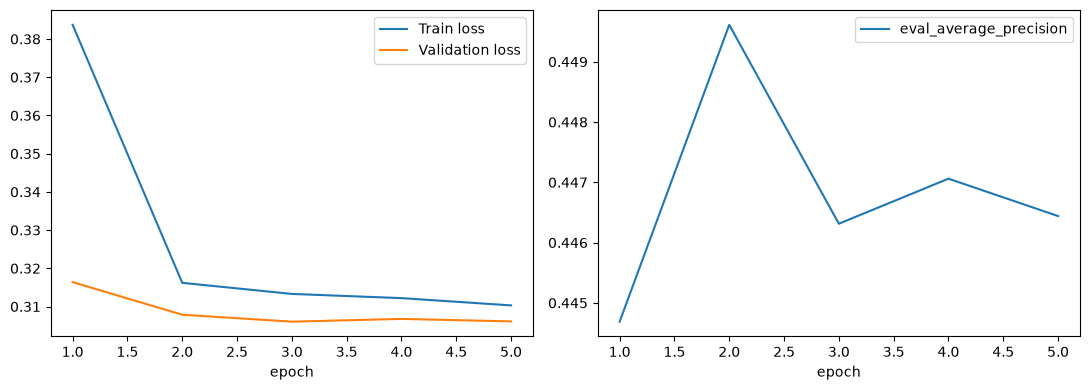

### seed=17: failure_within_30d

,precision,recall,f1-score,support
0,0.834473,1.000000,0.909769,1830.000000
1,0.000000,0.000000,0.000000,363.000000
accuracy,0.834473,0.834473,0.834473,0.834473
macro avg,0.417237,0.500000,0.454884,2193.000000
weighted avg,0.696346,0.834473,0.759178,2193.000000


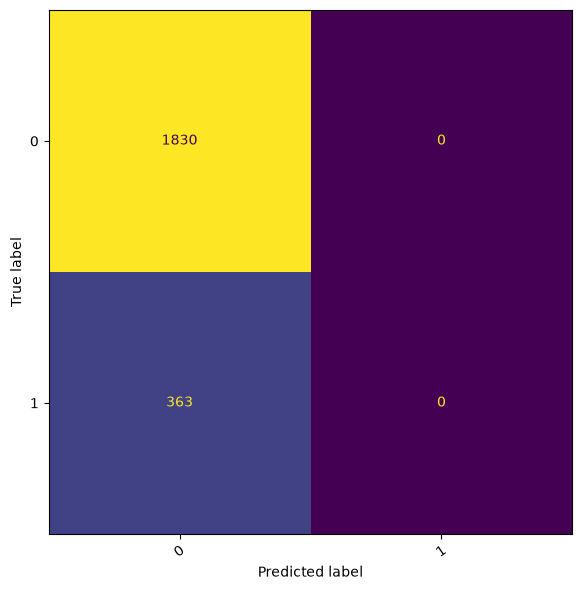

Ошибок validation: **363**.

,id,y_true,y_pred,probability_0,probability_1,operator_log,equipment,severity
12,112,1,0,0.612414,0.387586,Оператор отмечает нарастающий гул в зоне подши...,CP-500,medium
16,125,1,0,0.890543,0.109457,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium
21,162,1,0,0.661734,0.338266,Зафиксирован устойчивый рост температуры корпу...,FV-40,high
32,214,1,0,0.524038,0.475962,"Слышен характерный шум, давление нестабильно, ...",PN-200,medium
33,215,1,0,0.653415,0.346585,Зафиксирован устойчивый рост температуры корпу...,TR-90,medium
34,228,1,0,0.609444,0.390556,Оператор отмечает нарастающий гул в зоне подши...,FV-40,medium
48,327,1,0,0.524038,0.475962,"Слышен характерный шум, давление нестабильно, ...",PN-200,high
49,332,1,0,0.891470,0.108530,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,medium
50,335,1,0,0.651887,0.348113,Зафиксирован устойчивый рост температуры корпу...,PN-300,medium
52,344,1,0,0.524038,0.475962,"Слышен характерный шум, давление нестабильно, ...",CP-500,high


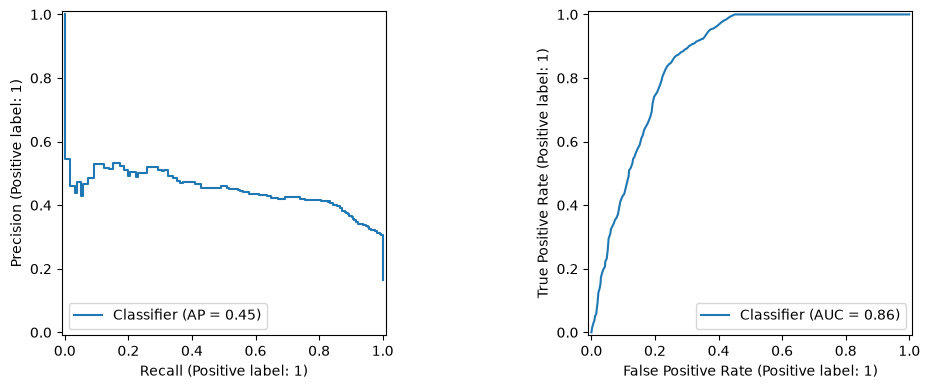

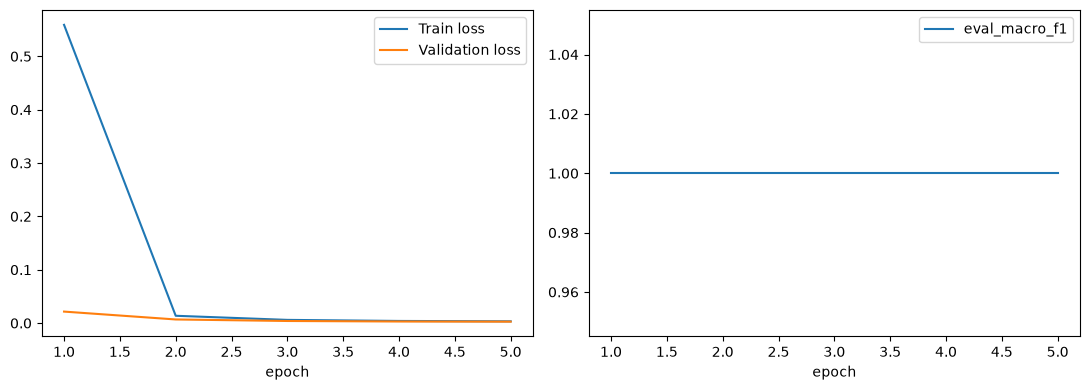

### seed=17: fault_type

,precision,recall,f1-score,support
bearing_wear,1.0,1.0,1.0,255.0
cavitation,1.0,1.0,1.0,222.0
imbalance,1.0,1.0,1.0,232.0
normal,1.0,1.0,1.0,1005.0
overheat,1.0,1.0,1.0,252.0
seal_leak,1.0,1.0,1.0,227.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,2193.0
weighted avg,1.0,1.0,1.0,2193.0


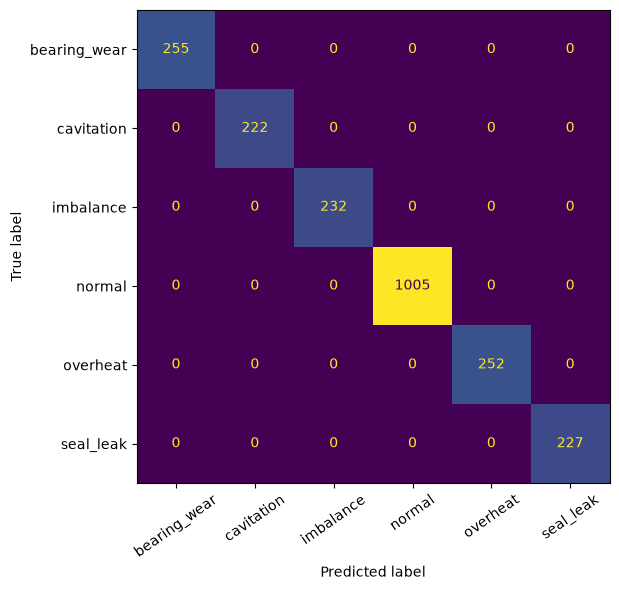

Ошибок validation: **0**.

,id,y_true,y_pred,probability_bearing_wear,probability_cavitation,probability_imbalance,probability_normal,probability_overheat,probability_seal_leak,operator_log,equipment,severity


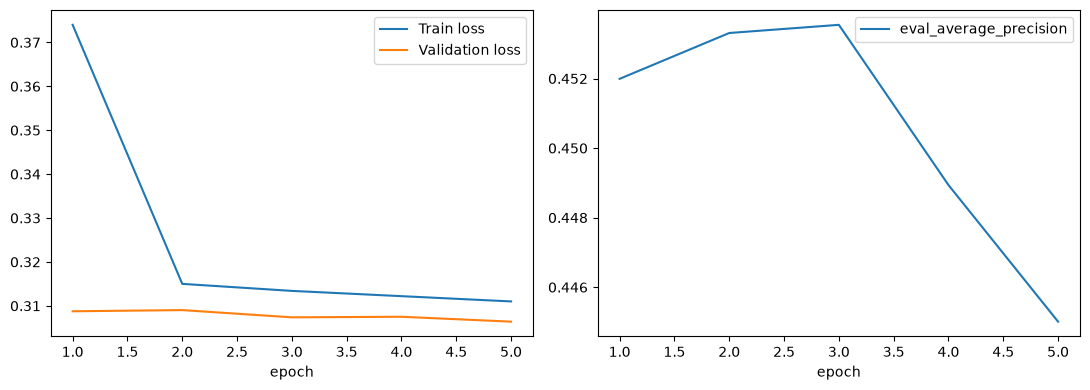

### seed=123: failure_within_30d

,precision,recall,f1-score,support
0,0.873161,0.940437,0.905551,1830.000000
1,0.509009,0.311295,0.386325,363.000000
accuracy,0.836297,0.836297,0.836297,0.836297
macro avg,0.691085,0.625866,0.645938,2193.000000
weighted avg,0.812884,0.836297,0.819605,2193.000000


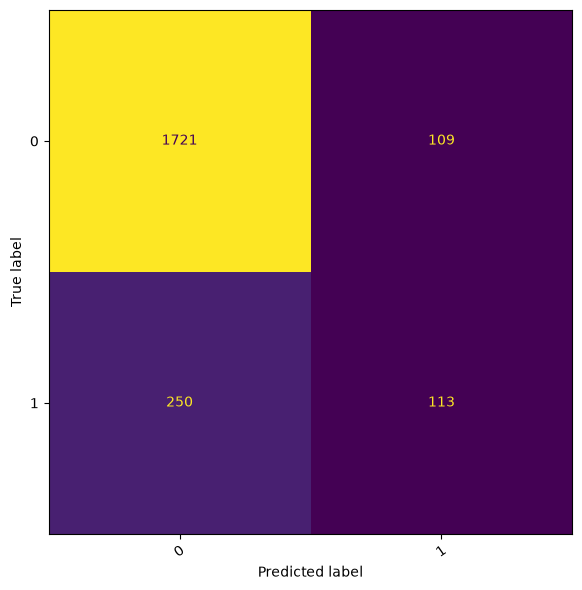

Ошибок validation: **359**.

,id,y_true,y_pred,probability_0,probability_1,operator_log,equipment,severity
2,14,0,1,0.480788,0.519212,"Слышен характерный шум, давление нестабильно, ...",PN-200,low
4,41,0,1,0.493263,0.506737,"Слышен характерный шум, давление нестабильно, ...",TR-90,medium
8,85,0,1,0.494987,0.505013,"Слышен характерный шум, давление нестабильно, ...",TR-90,medium
12,112,1,0,0.601439,0.398561,Оператор отмечает нарастающий гул в зоне подши...,CP-500,medium
16,125,1,0,0.858116,0.141884,Обнаружены следы утечки в зоне уплотнения и сн...,PN-300,medium
21,162,1,0,0.629738,0.370262,Зафиксирован устойчивый рост температуры корпу...,FV-40,high
30,201,0,1,0.479432,0.520568,"Слышен характерный шум, давление нестабильно, ...",PN-200,medium
33,215,1,0,0.611075,0.388925,Зафиксирован устойчивый рост температуры корпу...,TR-90,medium
34,228,1,0,0.582942,0.417058,Оператор отмечает нарастающий гул в зоне подши...,FV-40,medium
49,332,1,0,0.825256,0.174744,Обнаружены следы утечки в зоне уплотнения и сн...,TR-90,medium


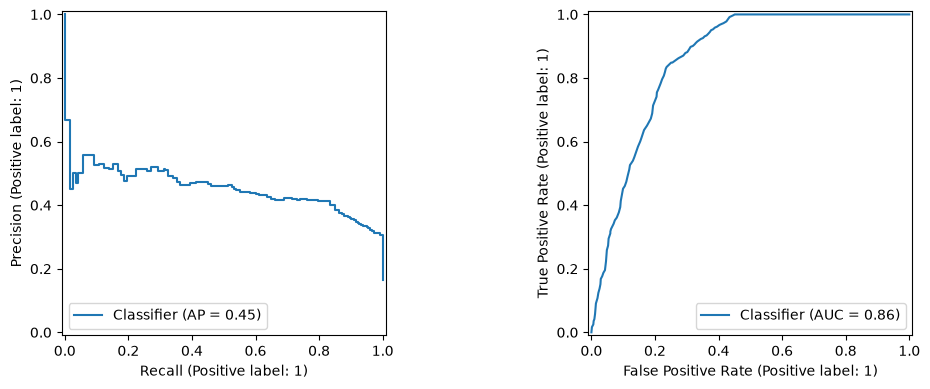

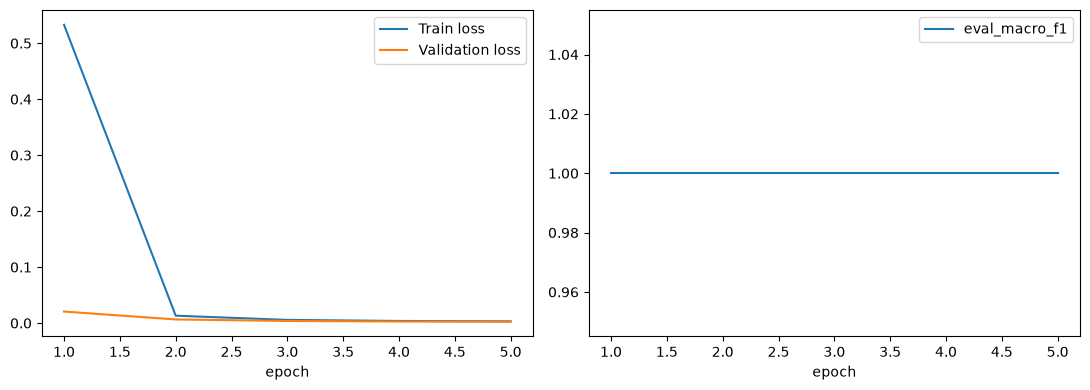

### seed=123: fault_type

,precision,recall,f1-score,support
bearing_wear,1.0,1.0,1.0,255.0
cavitation,1.0,1.0,1.0,222.0
imbalance,1.0,1.0,1.0,232.0
normal,1.0,1.0,1.0,1005.0
overheat,1.0,1.0,1.0,252.0
seal_leak,1.0,1.0,1.0,227.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,2193.0
weighted avg,1.0,1.0,1.0,2193.0


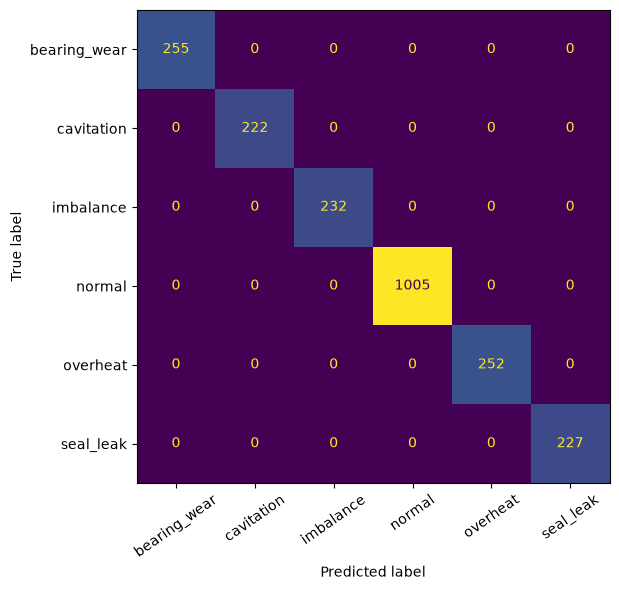

Ошибок validation: **0**.

,id,y_true,y_pred,probability_bearing_wear,probability_cavitation,probability_imbalance,probability_normal,probability_overheat,probability_seal_leak,operator_log,equipment,severity


In [14]:
if CHECKS["reuse_fitted_batch"] is None:
    for row in results:
        experiment_seed = row["seed"]
        target = row["target"]
        classes = CONFIG["expected_classes"][target]
        directory = PROJECT_ROOT / row["run_path"]
        predictions = prediction_tables[
            (experiment_seed, target, "validation")
        ]
        history = json.loads((directory / "history.json").read_text())
        history_frame = pd.DataFrame(history)
        metric = "eval_" + CONFIG["targets"][target]
        figure, axes = plt.subplots(1, 2, figsize=(11, 4))
        history_frame.dropna(subset=["loss"]).plot(
            x="epoch", y="loss", ax=axes[0], label="Train loss"
        )
        history_frame.dropna(subset=["eval_loss"]).plot(
            x="epoch", y="eval_loss", ax=axes[0], label="Validation loss"
        )
        history_frame.dropna(subset=[metric]).plot(
            x="epoch", y=metric, ax=axes[1], label=metric
        )
        figure.tight_layout()
        figure.savefig(directory / "learning_curves.png")
        plt.show()
        plt.close(figure)
        report = pd.DataFrame(
            classification_report(
                predictions.y_true,
                predictions.y_pred,
                labels=classes,
                output_dict=True,
                zero_division=0,
            )
        ).T
        report.to_csv(directory / "classification_report.csv")
        display(Markdown(f"### seed={experiment_seed}: {target}"))
        display(report)
        matrix = confusion_matrix(
            predictions.y_true, predictions.y_pred, labels=classes
        )
        pd.DataFrame(matrix, index=classes, columns=classes).to_csv(
            directory / "confusion_matrix.csv"
        )
        figure, axis = plt.subplots(figsize=(8, 6))
        ConfusionMatrixDisplay(matrix, display_labels=classes).plot(
            ax=axis, colorbar=False, xticks_rotation=35
        )
        figure.tight_layout()
        figure.savefig(directory / "confusion_matrix.png")
        plt.show()
        plt.close(figure)
        diagnosis = predictions.merge(
            validation[["id", "operator_log", "equipment", "severity"]],
            on="id",
            validate="one_to_one",
        )
        errors = diagnosis.loc[diagnosis.y_true.ne(diagnosis.y_pred)]
        errors.head(CONFIG["error_examples"]).to_csv(
            directory / "error_examples.csv", index=False
        )
        display(Markdown(f"Ошибок validation: **{len(errors)}**."))
        display(errors.head(CONFIG["error_examples"]))
        subgroups = []
        for grouping in ["equipment", "severity"]:
            for value, group in diagnosis.groupby(grouping):
                subgroups.append(
                    {
                        "grouping": grouping,
                        "value": value,
                        "rows": len(group),
                        **baseline.classification_metrics(
                            group, classes, target
                        ),
                    }
                )
        pd.DataFrame(subgroups).to_csv(
            directory / "subgroups.csv", index=False
        )
        if target == "failure_within_30d":
            figure, axes = plt.subplots(1, 2, figsize=(11, 4))
            PrecisionRecallDisplay.from_predictions(
                predictions.y_true, predictions.probability_1, ax=axes[0]
            )
            RocCurveDisplay.from_predictions(
                predictions.y_true, predictions.probability_1, ax=axes[1]
            )
            figure.tight_layout()
            figure.savefig(directory / "pr_roc.png")
            plt.show()
            plt.close(figure)

In [15]:
if CHECKS["reuse_fitted_batch"] is None:
    binary_target = "failure_within_30d"
    thresholds = {}
    for binary_row in results:
        if binary_row["target"] != binary_target:
            continue
        experiment_seed = binary_row["seed"]
        binary_directory = PROJECT_ROOT / binary_row["run_path"]
        original = prediction_tables[
            (experiment_seed, binary_target, "validation")
        ]
        best_threshold, curve = baseline.select_failure_threshold(
            original.y_true,
            original.probability_1,
            CONFIG["selection_decimals"],
        )
        np.testing.assert_array_equal(
            original.probability_1.ge(best_threshold["threshold"]),
            reloaded_predictions[
                (experiment_seed, binary_target)
            ].probability_1.ge(best_threshold["threshold"]),
        )
        curve.to_csv(binary_directory / "threshold_curve.csv", index=False)
        write_json(
            binary_directory / "model/decision_rule.json",
            {
                "positive_class": 1,
                "threshold": best_threshold["threshold"],
                "rule": "probability_1 >= threshold",
                "selection_split": "validation",
                "selection_metric": "f2",
                "refit": False,
            },
        )
        threshold_metrics = []
        for split in ["train", "validation"]:
            predictions = prediction_tables[
                (experiment_seed, binary_target, split)
            ].copy()
            predictions["y_pred"] = predictions.probability_1.ge(
                best_threshold["threshold"]
            ).astype(int)
            predictions.to_csv(
                binary_directory / f"{split}_predictions_f2.csv", index=False
            )
            before = baseline.classification_metrics(
                prediction_tables[(experiment_seed, binary_target, split)],
                [0, 1],
                binary_target,
            )
            after = baseline.classification_metrics(
                predictions, [0, 1], binary_target
            )
            assert before["average_precision"] == after["average_precision"]
            assert before["roc_auc"] == after["roc_auc"]
            for name, values in [
                ("default_0.5", before),
                ("selected_f2", after),
            ]:
                threshold_metrics.append(
                    {"split": split, "rule": name, **values}
                )
            prediction_tables[
                (experiment_seed, binary_target, split + "_f2")
            ] = predictions
            if split == "validation":
                pd.DataFrame(
                    confusion_matrix(
                        predictions.y_true, predictions.y_pred, labels=[0, 1]
                    ),
                    index=[0, 1],
                    columns=[0, 1],
                ).to_csv(binary_directory / "confusion_matrix_f2.csv")
        pd.DataFrame(threshold_metrics).to_csv(
            binary_directory / "threshold_metrics.csv", index=False
        )
        operating_points = [
            baseline.precision_recall_operating_point(
                curve, floor, CONFIG["selection_decimals"]
            )
            for floor in CONFIG["precision_floors"]
        ]
        pd.DataFrame(operating_points).to_csv(
            binary_directory / "precision_operating_points.csv", index=False
        )
        display(pd.DataFrame(threshold_metrics))
        display(pd.DataFrame(operating_points))
        with mlflow.start_run(run_id=binary_row["run_id"]):
            mlflow.log_param("f2_threshold", best_threshold["threshold"])
            mlflow.log_metrics(
                {
                    "validation_f2_threshold_" + key: value
                    for key, value in baseline.classification_metrics(
                        prediction_tables[
                            (experiment_seed, binary_target, "validation_f2")
                        ],
                        [0, 1],
                        binary_target,
                    ).items()
                    if value is not None
                }
            )
        thresholds[experiment_seed] = best_threshold

,split,rule,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision
0,train,default_0.5,0.832473,0.454289,0.312173,0.000000,0.000000,0.000000,0.000000,0.858570,0.464331
1,train,selected_f2,0.740310,0.674877,0.312173,0.379951,0.870588,0.529021,0.691897,0.858570,0.464331
2,validation,default_0.5,0.834473,0.454884,0.307857,0.000000,0.000000,0.000000,0.000000,0.858885,0.448240
3,validation,selected_f2,0.755586,0.687266,0.307857,0.392547,0.870523,0.541096,0.700044,0.858885,0.448240


,precision_floor,status,threshold,precision,recall,f1,f2,tp,fp,tn,fn
0,0.7,unattainable,None,None,None,None,None,None,None,None,None
1,0.8,unattainable,None,None,None,None,None,None,None,None,None


,split,rule,accuracy,macro_f1,log_loss,precision,recall,f1,f2,roc_auc,average_precision
0,train,default_0.5,0.837447,0.620638,0.310389,0.532515,0.243137,0.333846,0.272784,0.860406,0.467310
1,train,selected_f2,0.767902,0.695266,0.310389,0.406216,0.834734,0.546488,0.689304,0.860406,0.467310
2,validation,default_0.5,0.836297,0.645938,0.307378,0.509009,0.311295,0.386325,0.337515,0.857970,0.453008
3,validation,selected_f2,0.765618,0.693635,0.307378,0.401565,0.848485,0.545133,0.694006,0.857970,0.453008


,precision_floor,status,threshold,precision,recall,f1,f2,tp,fp,tn,fn
0,0.7,unattainable,None,None,None,None,None,None,None,None,None
1,0.8,unattainable,None,None,None,None,None,None,None,None,None


## 14. Прежние парные сравнения для двух новых seed

Для каждого seed шесть AP/macro-F1 и три F2: всего 18 сравнений,
по 2 000 групповых повторов. Это интервалы фиксированных прогнозов
после выбора на validation; разброс обучения по seed — другой расчёт.


In [16]:
if CHECKS["reuse_fitted_batch"] is None:
    validation_groups = membership.loc[
        membership["split"].eq("validation"), ["id", "group_id"]
    ]
    comparisons = []
    for experiment_seed in CHECKS["seeds"]:
        original = prediction_tables[
            (experiment_seed, binary_target, "validation")
        ]
        for (name, target), reference in references.items():
            comparisons.append(
                {
                    "seed": experiment_seed,
                    "target": target,
                    "reference": name,
                    **paired_group_bootstrap(
                        reference["predictions"],
                        prediction_tables[
                            (experiment_seed, target, "validation")
                        ],
                        validation_groups,
                        CONFIG["expected_classes"][target],
                        target,
                        **CONFIG["bootstrap"],
                    ),
                }
            )
        f2_references = {"default_0.5": original}
        for name in ["tfidf", "catboost_numeric"]:
            f2_references[name] = pd.read_csv(
                references[(name, binary_target)]["directory"]
                / "validation_predictions_f2.csv",
                dtype={"id": "string"},
                float_precision="round_trip",
            )
        for name, predictions in f2_references.items():
            comparisons.append(
                {
                    "seed": experiment_seed,
                    "target": binary_target,
                    "reference": name,
                    **paired_group_bootstrap(
                        predictions,
                        prediction_tables[
                            (experiment_seed, binary_target, "validation_f2")
                        ],
                        validation_groups,
                        [0, 1],
                        binary_target,
                        metric="f2",
                        **CONFIG["bootstrap"],
                    ),
                }
            )

    assert len(comparisons) == 18
    comparison_results = pd.DataFrame(comparisons)
    comparison_results.to_csv(
        batch_directory / "paired_bootstrap.csv", index=False
    )
    display(comparison_results)

,seed,target,reference,metric,reference_score,candidate_score,difference,lower_95,upper_95,groups,requested_repeats,valid_repeats,skipped_repeats,direction
0,42,failure_within_30d,tfidf,average_precision,0.442193,0.448240,0.006047,-0.012044,0.022255,59,2000,2000,0,candidate - reference
1,42,fault_type,tfidf,macro_f1,1.000000,1.000000,0.000000,0.000000,0.000000,59,2000,2000,0,candidate - reference
2,42,failure_within_30d,catboost_numeric,average_precision,0.786742,0.448240,-0.338503,-0.378735,-0.295763,59,2000,2000,0,candidate - reference
3,42,fault_type,catboost_numeric,macro_f1,0.757161,1.000000,0.242839,0.222900,0.279652,59,2000,2000,0,candidate - reference
4,42,failure_within_30d,prior,average_precision,0.165527,0.448240,0.282713,0.205852,0.348072,59,2000,2000,0,candidate - reference
5,42,fault_type,prior,macro_f1,0.104753,1.000000,0.895247,0.873183,0.930498,59,2000,2000,0,candidate - reference
6,42,failure_within_30d,default_0.5,f2,0.000000,0.700044,0.700044,0.639886,0.746276,59,2000,2000,0,candidate - reference
7,42,failure_within_30d,tfidf,f2,0.694444,0.700044,0.005600,-0.002991,0.020265,59,2000,2000,0,candidate - reference
8,42,failure_within_30d,catboost_numeric,f2,0.827506,0.700044,-0.127462,-0.167021,-0.097526,59,2000,2000,0,candidate - reference
9,42,failure_within_30d,tfidf,average_precision,0.442193,0.453008,0.010815,-0.006193,0.025565,59,2000,2000,0,candidate - reference


In [17]:
if CHECKS["reuse_fitted_batch"] is None:
    assert len(results) == STAGE_CONFIG["expected_training_runs"]
    assert data.file_sha256(membership_path) == CONFIG["membership_sha256"]
    assert (
        data.file_sha256(PROJECT_ROOT / dataset_config["dataset"])
        == dataset_config["sha256"]
    )
    for relative, checksum in reference_checksums.items():
        assert data.file_sha256(PROJECT_ROOT / relative) == checksum
    for row in results:
        with mlflow.start_run(run_id=row["run_id"]):
            directory = PROJECT_ROOT / row["run_path"]
            for path in directory.iterdir():
                if path.is_file():
                    mlflow.log_artifact(str(path))
            if row["target"] == binary_target:
                mlflow.log_artifact(
                    str(directory / "model/decision_rule.json")
                )
        assert mlflow.get_run(row["run_id"]).info.status == "FINISHED"
    manifest.update(
        {
            "status": "completed",
            "finished_at_utc": datetime.now(timezone.utc).isoformat(),
            "selected_models": results,
            "bootstrap_comparisons": len(comparisons),
            "thresholds": thresholds,
            "test_evaluated": False,
        }
    )
    write_json(batch_directory / "manifest.json", manifest)
    summary = [
        "# RuBERT-tiny2: выполненный опыт B",
        "",
        "Четыре обучения: seeds 17/123, две цели, пять эпох; operator_log.",
        "Test не оценивался. Число сравнений: 18.",
        "",
    ]
    for row in results:
        metric = CONFIG["targets"][row["target"]]
        summary.append(
            f"- seed={row['seed']}; {row['target']}: "
            f"{metric}={row[metric]:.6f}; "
            f"эпоха={row['best_epoch']}; fit={row['fit_seconds']:.2f} с."
        )
    summary.extend(
        [
            "",
            f"F2-пороги: {thresholds!r}.",
            "",
            "Выбор эпохи и порога на одной validation; оценки условны.",
            "Шесть шаблонов ограничивают перенос на неизвестные формулировки.",
            "Бутстрэп не оценивает вариативность повторного обучения.",
        ]
    )
    (batch_directory / "summary.md").write_text(
        "\n".join(summary), encoding="utf-8"
    )
    logger.info("Завершено: %s", batch_directory)
    display(Markdown("\n".join(summary)))

2026-10-18 15:01:22,280 Завершено: C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\artifacts\experiments\rubert_tiny2_seed_checks_20261018T114619_318668Z


# RuBERT-tiny2: выполненный опыт B

Четыре обучения: seeds 17/123, две цели, пять эпох; operator_log.
Test не оценивался. Число сравнений: 18.

- seed=17; failure_within_30d: average_precision=0.448240; эпоха=2.0; fit=200.26 с.
- seed=17; fault_type: macro_f1=1.000000; эпоха=1.0; fit=184.96 с.
- seed=123; failure_within_30d: average_precision=0.453008; эпоха=3.0; fit=184.35 с.
- seed=123; fault_type: macro_f1=1.000000; эпоха=1.0; fit=186.83 с.

F2-пороги: {17: {'threshold': 0.19644376520223875, 'precision': 0.39254658385093166, 'recall': 0.8705234159779615, 'f1': 0.541095890410959, 'f2': 0.7000443066016836, 'tp': 316, 'fp': 489, 'tn': 1341, 'fn': 47}, 123: {'threshold': 0.19270297174072445, 'precision': 0.4015645371577575, 'recall': 0.8484848484848485, 'f1': 0.5451327433628319, 'f2': 0.694006309148265, 'tp': 308, 'fp': 459, 'tn': 1371, 'fn': 55}}.

Выбор эпохи и порога на одной validation; оценки условны.
Шесть шаблонов ограничивают перенос на неизвестные формулировки.
Бутстрэп не оценивает вариативность повторного обучения.

## 15. Разброс по трём seed без выбора победителя

Seed 42 повторно не обучается. Показываем все три результата,
среднее, стандартное отклонение ddof=1, минимум и максимум.
Три seed — небольшая описательная проверка; это не доверительный
интервал по всем возможным обучениям и не независимая test-оценка.


In [18]:
seed_records = []
for seed, batch in [
    (CHECKS["reference_seed"], reference_batch),
    *[(seed, batch_directory) for seed in CHECKS["seeds"]],
]:
    selected = pd.read_csv(batch / "selected_models.csv")
    if "seed" in selected:
        selected = selected.loc[selected.seed.eq(seed)]
    assert len(selected) == 2
    for row in selected.to_dict("records"):
        directory = PROJECT_ROOT / row["run_path"]
        trial = json.loads((directory / "manifest.json").read_text())
        assert trial["config"]["seed"] == seed
        values = {"seed": seed, **row}
        if row["target"] == "failure_within_30d":
            rule = json.loads(
                (directory / "model/decision_rule.json").read_text()
            )
            values["f2_threshold"] = rule["threshold"]
            threshold_scores = pd.read_csv(directory / "threshold_metrics.csv")
            selected_score = threshold_scores.loc[
                threshold_scores.split.eq("validation")
                & threshold_scores.rule.eq("selected_f2")
            ].iloc[0]
            for metric in ["precision", "recall", "f1", "f2"]:
                values["selected_" + metric] = selected_score[metric]
        seed_records.append(values)
seed_results = pd.DataFrame(seed_records)
seed_statistics = []
for target, group in seed_results.groupby("target"):
    metrics = [CONFIG["targets"][target]]
    if target == "failure_within_30d":
        metrics += [
            "f2_threshold",
            "selected_precision",
            "selected_recall",
            "selected_f1",
            "selected_f2",
        ]
    for metric in metrics:
        scores = group[metric]
        seed_statistics.append(
            {
                "target": target,
                "metric": metric,
                "seeds": len(scores),
                "mean": scores.mean(),
                "std_ddof_1": scores.std(ddof=1),
                "minimum": scores.min(),
                "maximum": scores.max(),
            }
        )
seed_summary = pd.DataFrame(seed_statistics)
if CHECKS["reuse_fitted_batch"] is None:
    seed_results.to_csv(batch_directory / "seed_results.csv", index=False)
    seed_summary.to_csv(batch_directory / "seed_summary.csv", index=False)
display(seed_results)
display(seed_summary)

,seed,target,run_id,run_path,best_epoch,fit_seconds,accuracy,macro_f1,log_loss,precision,...,f1,f2,roc_auc,average_precision,prediction_seconds,f2_threshold,selected_precision,selected_recall,selected_f1,selected_f2
0,42,failure_within_30d,4451337cd8ae423fa077456ea0cb4d0a,artifacts/experiments/rubert_tiny2_20261018T11...,3.0,199.475798,0.836297,0.645938,0.306624,0.509009,...,0.386325,0.337515,0.858636,0.450304,0.794209,0.130998,0.371429,0.895317,0.525040,0.698324
1,42,fault_type,f93cce6aad02443f83df97faa55887ce,artifacts/experiments/rubert_tiny2_20261018T11...,1.0,201.269227,1.000000,1.000000,0.020255,NaN,...,NaN,NaN,NaN,NaN,0.812894,NaN,NaN,NaN,NaN,NaN
2,17,failure_within_30d,ce4523392fbc435fbd57746337ace52a,artifacts/experiments/rubert_tiny2_seed_checks...,2.0,200.263853,0.834473,0.454884,0.307857,0.000000,...,0.000000,0.000000,0.858885,0.448240,0.686580,0.196444,0.392547,0.870523,0.541096,0.700044
3,17,fault_type,79e3ee2b47c141a694860e8d1a02950d,artifacts/experiments/rubert_tiny2_seed_checks...,1.0,184.955168,1.000000,1.000000,0.021541,NaN,...,NaN,NaN,NaN,NaN,0.567519,NaN,NaN,NaN,NaN,NaN
4,123,failure_within_30d,a83b998987a5404494344389ee3a5f58,artifacts/experiments/rubert_tiny2_seed_checks...,3.0,184.352333,0.836297,0.645938,0.307378,0.509009,...,0.386325,0.337515,0.857970,0.453008,0.606126,0.192703,0.401565,0.848485,0.545133,0.694006
5,123,fault_type,e1252b58e824482091cb3174dac90081,artifacts/experiments/rubert_tiny2_seed_checks...,1.0,186.828120,1.000000,1.000000,0.020595,NaN,...,NaN,NaN,NaN,NaN,0.779498,NaN,NaN,NaN,NaN,NaN


,target,metric,seeds,mean,std_ddof_1,minimum,maximum
0,failure_within_30d,average_precision,3,0.450517,0.002391,0.448240,0.453008
1,failure_within_30d,f2_threshold,3,0.173382,0.036753,0.130998,0.196444
2,failure_within_30d,selected_precision,3,0.388513,0.015468,0.371429,0.401565
3,failure_within_30d,selected_recall,3,0.871442,0.023429,0.848485,0.895317
4,failure_within_30d,selected_f1,3,0.537090,0.010628,0.525040,0.545133
5,failure_within_30d,selected_f2,3,0.697458,0.003111,0.694006,0.700044
6,fault_type,macro_f1,3,1.000000,0.000000,1.000000,1.000000


## 16. Синтетические переформулировки: закреплённые пары

24 текста, шесть источников validation, четыре стиля на источник.
Файл WORDING_REVIEW.md предназначен для проверки смысла человеком;
статус review сохраняется явно и не подменяется проверкой программы.
Никакого обучения, выбора seed, эпохи или порога по этим текстам нет.
Метка диагноза наследуется от источника; это не экспертная разметка.
Для отказа сохраняются только изменения вероятностей и решений:
синтетические метки failure_within_30d не создаются.


In [19]:
WORDING = CONFIG["wording_check"]
challenge_path = PROJECT_ROOT / WORDING["file"]
assert data.file_sha256(challenge_path) == WORDING["sha256"]
payload = json.loads(challenge_path.read_text(encoding="utf-8"))
review_path = PROJECT_ROOT / WORDING["review_file"]
review = json.loads(review_path.read_text(encoding="utf-8"))
assert payload["human_review_status"] == review["status"] == "approved"
pairs = validate_wording_pairs(
    payload,
    validation,
    pd.concat([train.operator_log, validation.operator_log]),
)
assert len(pairs) == WORDING["expected_pairs"]
assert pairs.source_id.nunique() == WORDING["expected_sources"]
assert set(pairs.id) == set(review["reviewed_ids"])
assert pairs.groupby("fault_type").size().eq(4).all()
wording_started = datetime.now(timezone.utc)
wording_directory = (
    PROJECT_ROOT
    / CONFIG["output_root"]
    / (WORDING["batch_prefix"] + wording_started.strftime("%Y%m%dT%H%M%S_%fZ"))
)
wording_directory.mkdir(parents=True, exist_ok=False)
pairs.to_csv(wording_directory / "synthetic_pairs.csv", index=False)
shutil.copy2(challenge_path, wording_directory / "challenge.json")
shutil.copy2(review_path, wording_directory / "human_review.json")
write_json(wording_directory / "config.json", CONFIG)
wording_manifest = {
    "status": "running",
    "dataset_kind": "synthetic_wording_check",
    "human_review": review,
    "challenge_sha256": WORDING["sha256"],
    "review_sha256": data.file_sha256(review_path),
    "pairs": len(pairs),
    "source_observations": pairs.source_id.nunique(),
    "seeds": [42, 17, 123],
    "new_training_runs": 0,
    "failure_labels_available": False,
    "test_evaluated": False,
    "libraries": versions,
    "hardware": hardware,
    "source_model_checksums": {},
}
write_json(wording_directory / "manifest.json", wording_manifest)
input_records = []
for kind, column in [
    ("original", "source_operator_log"),
    ("paraphrase", "operator_log"),
]:
    for row in pairs.to_dict("records"):
        input_records.append(
            {
                "id": row["id"] + "__" + kind,
                "pair_id": row["id"],
                "source_id": row["source_id"],
                "kind": kind,
                "operator_log": row[column],
                "inherited_fault_type": row["fault_type"],
                "style": row["style"],
                "synthetic": True,
            }
        )
wording_inputs = pd.DataFrame(input_records)
wording_inputs.to_csv(wording_directory / "inputs.csv", index=False)
model_sources = []
for target in CONFIG["targets"]:
    model_sources.append(
        {
            "name": "tfidf",
            "target": target,
            "seed": None,
            "directory": references[("tfidf", target)]["directory"],
        }
    )
for row in seed_results.to_dict("records"):
    model_sources.append(
        {
            "name": "rubert_" + str(int(row["seed"])),
            "seed": int(row["seed"]),
            "target": row["target"],
            "directory": PROJECT_ROOT / row["run_path"],
        }
    )
assert len(model_sources) == 8
display(pairs[["id", "source_id", "fault_type", "style", "operator_log"]])

,id,source_id,fault_type,style,operator_log
0,normal_order,5,normal,word_order,"При нагрузке 46% посторонних шумов нет, оборуд..."
1,normal_synonyms,5,normal,synonyms,Агрегат функционирует ровно; никаких необычных...
2,normal_short,5,normal,short_note,Нагрузка: 46%. Режим устойчивый. Чуждых работе...
3,normal_conversational,5,normal,conversational,На 46% нагрузки всё работает ровно. Каких-либо...
4,seal_order,13,seal_leak,word_order,При нагрузке 93% давление снизилось; возле упл...
5,seal_synonyms,13,seal_leak,synonyms,"Уплотнительный узел имеет признаки подтекания,..."
6,seal_short,13,seal_leak,short_note,Нагрузка: 93%. Подтекание около уплотнения. От...
7,seal_conversational,13,seal_leak,conversational,Работаем на 93% нагрузки. В районе уплотнения ...
8,cavitation_order,14,cavitation,word_order,При нагрузке 50% наблюдается вибрация и нестаб...
9,cavitation_synonyms,14,cavitation,synonyms,"На половинной загрузке, 50%, агрегат дрожит, н..."


## 17. TF-IDF и три seed RuBERT на одинаковых парах

Модели и токенизаторы читаются из закреплённых каталогов.
Предобработка не обучается, F2-пороги остаются сохранёнными.
Это качественная проверка 24 рукописных вариантов шести
наблюдений; числовые итоги не оценивают качество на новых данных.


In [20]:
wording_summaries = []
wording_details = []
inference_records = []
for source in model_sources:
    name, target = source["name"], source["target"]
    directory = source["directory"]
    classes = CONFIG["expected_classes"][target]
    saved_manifest = json.loads((directory / "manifest.json").read_text())
    assert saved_manifest["features"] == ["operator_log"]
    assert saved_manifest["classes"] == classes
    assert not set(CONFIG["excluded_features"]).intersection(
        saved_manifest["features"]
    )
    if target == "failure_within_30d":
        threshold_path = (
            directory / "model/decision_rule.json"
            if name != "tfidf"
            else directory / "threshold_selection/manifest.json"
        )
        threshold_info = json.loads(threshold_path.read_text())
        fixed_threshold = (
            threshold_info["threshold"]
            if name != "tfidf"
            else threshold_info["selected_threshold"]
        )
    else:
        fixed_threshold = 0.5
    inference_start = perf_counter()
    if name == "tfidf":
        model_path = directory / "model.pkl"
        with model_path.open("rb") as handle:
            classifier = pickle.load(handle)
        assert classifier.classes_.tolist() == classes
        probabilities = classifier.predict_proba(wording_inputs.operator_log)
        del classifier
        files = [model_path, directory / "manifest.json"]
    else:
        classifier = AutoModelForSequenceClassification.from_pretrained(
            directory / "model",
            local_files_only=True,
            attn_implementation="eager",
        ).to(DEVICE)
        classifier.eval()
        assert [
            classifier.config.id2label[i] for i in range(len(classes))
        ] == ([str(label) for label in classes])
        saved_tokenizer = AutoTokenizer.from_pretrained(
            directory / "model", local_files_only=True
        )
        tokens = saved_tokenizer(
            text_transformer.text_inputs(wording_inputs[CONFIG["features"]]),
            padding=True,
            truncation=True,
            max_length=CONFIG["max_length"],
            return_tensors="pt",
        ).to(DEVICE)
        with torch.no_grad():
            logits = classifier(**tokens).logits.cpu().numpy()
        probabilities = softmax(logits.astype(float), axis=1)
        del classifier, tokens
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
        files = list((directory / "model").glob("*"))
    if target == "failure_within_30d":
        files.append(threshold_path)
    for model_file in files:
        relative = model_file.relative_to(PROJECT_ROOT).as_posix()
        wording_manifest["source_model_checksums"][relative] = (
            data.file_sha256(model_file)
        )
    predictions = wording_prediction_table(
        wording_inputs.id, probabilities, classes, target, fixed_threshold
    ).merge(
        wording_inputs.drop(columns="operator_log"),
        on="id",
        validate="one_to_one",
        sort=False,
    )
    predictions.to_csv(
        wording_directory / f"{name}_{target}_predictions.csv", index=False
    )
    inference_records.append(
        {
            "model": name,
            "target": target,
            "rows": len(predictions),
            "seconds": perf_counter() - inference_start,
            "model_path": directory.relative_to(PROJECT_ROOT).as_posix(),
            "fixed_threshold": fixed_threshold,
        }
    )
    original_predictions = (
        predictions.loc[predictions.kind.eq("original")]
        .set_index("pair_id")
        .sort_index()
    )
    rewrites = (
        predictions.loc[predictions.kind.eq("paraphrase")]
        .set_index("pair_id")
        .sort_index()
    )
    assert original_predictions.index.equals(rewrites.index)
    assert original_predictions.source_id.equals(rewrites.source_id)
    details = pd.DataFrame(
        {
            "pair_id": rewrites.index,
            "source_id": rewrites.source_id.to_numpy(),
            "model": name,
            "target": target,
            "style": rewrites.style.to_numpy(),
            "original_prediction": original_predictions.y_pred.to_numpy(),
            "paraphrase_prediction": rewrites.y_pred.to_numpy(),
            "decision_changed": original_predictions.y_pred.ne(
                rewrites.y_pred
            ).to_numpy(),
        }
    )
    summary_row = {
        "model": name,
        "target": target,
        "pairs": len(details),
        "sources": details.source_id.nunique(),
        "decision_changes": int(details.decision_changed.sum()),
        "decision_agreement": float(1 - details.decision_changed.mean()),
        "fixed_threshold": fixed_threshold,
    }
    if target == "fault_type":
        for kind, table in [
            ("original", original_predictions),
            ("paraphrase", rewrites),
        ]:
            scored = table.copy()
            scored["y_true"] = scored.inherited_fault_type
            for metric, value in baseline.classification_metrics(
                scored, classes, target
            ).items():
                summary_row[kind + "_" + metric] = value
        details["inherited_fault_type"] = (
            rewrites.inherited_fault_type.to_numpy()
        )
        details["paraphrase_correct"] = rewrites.y_pred.eq(
            rewrites.inherited_fault_type
        ).to_numpy()
    else:
        change = rewrites.probability_1 - original_predictions.probability_1
        details["original_probability_1"] = (
            original_predictions.probability_1.to_numpy()
        )
        details["paraphrase_probability_1"] = rewrites.probability_1.to_numpy()
        details["probability_change"] = change.to_numpy()
        details["original_threshold_margin"] = (
            (original_predictions.probability_1 - fixed_threshold)
            .abs()
            .to_numpy()
        )
        summary_row.update(
            {
                "mean_absolute_probability_change": float(change.abs().mean()),
                "max_absolute_probability_change": float(change.abs().max()),
                "changes_above_1e_6": int((change.abs() > 1e-6).sum()),
                "decision_changes_at_0_5": int(
                    original_predictions.probability_1.ge(0.5)
                    .ne(rewrites.probability_1.ge(0.5))
                    .sum()
                ),
            }
        )
    wording_summaries.append(summary_row)
    wording_details.append(details)
wording_summary = pd.DataFrame(wording_summaries)
wording_detail = pd.concat(wording_details, ignore_index=True)
wording_summary.to_csv(wording_directory / "summary.csv", index=False)
wording_detail.to_csv(wording_directory / "paired_details.csv", index=False)
pd.DataFrame(inference_records).to_csv(
    wording_directory / "inference_sources.csv", index=False
)
for relative, checksum in wording_manifest["source_model_checksums"].items():
    assert data.file_sha256(PROJECT_ROOT / relative) == checksum
for relative, checksum in reference_checksums.items():
    assert data.file_sha256(PROJECT_ROOT / relative) == checksum
assert data.file_sha256(challenge_path) == WORDING["sha256"]
wording_manifest.update(
    {
        "status": "completed",
        "new_training_runs": 0,
        "finished_at_utc": datetime.now(timezone.utc).isoformat(),
        "limitations": [
            "24 synthetic rewrites of six validation observations",
            "diagnosis labels inherited from the generated dataset",
            "no failure labels or failure accuracy metrics",
            "no tuning or seed selection from this diagnostic",
        ],
    }
)
write_json(wording_directory / "manifest.json", wording_manifest)
display(wording_summary)
display(wording_detail.loc[wording_detail.decision_changed])
display(
    Markdown(
        "Результаты переформулировок: "
        + wording_directory.relative_to(PROJECT_ROOT).as_posix()
    )
)

AttributeError: 'Styler' object has no attribute 'to_numpy'